In [1]:
# Initialization of packages used

using Plots
using Distributions, Random, Statistics
using LinearAlgebra, SparseArrays, JSON
using Colors
using CSV
using DataFrames
using MLJ
using Dates

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

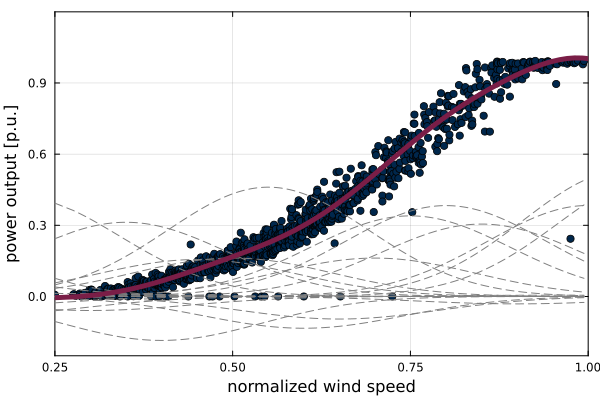

In [2]:
# 1 
# Example from ECE 598
# RBF-SVM for wind power curve fitting with Tikhonov regularization, wind power data example from ECE 598

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

dataset = JSON.parsefile("wind_power_data.json")

n = length(dataset["ActivePower"])

sort_index = sortperm(dataset["WindSpeed"])

t = Float64.(dataset["ActivePower"][sort_index])

x_raw = Float64.(dataset["WindSpeed"][sort_index])
x = x_raw ./ 10.0

# Parameters
α = 0.01          # learning rate
iter_max = 25_000 # maximum iterations
λ = 0.001         # regularization coefficient

reg_type = "l2"

c = collect(0.0:0.05:1.1)

num_centers = length(c)

γ = 5.0

# Gaussian RBF
function φ(x, j)
    return exp(-(γ * abs(x - c[j]))^2)
end


Φ = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ[i, j] = φ(x[i], j)
    end
end

Random.seed!(128)

w_0 = rand()

w = rand(num_centers)

# Stochastic Gradient Descent
for iteration in 1:iter_max

    # Randomly select one training sample
    i = rand(1:n)

    # RBF values for selected sample
    ϕi = Φ[i, :]

    y_hat = w_0 + dot(ϕi, w)

    # Error
    error = y_hat - t[i]

    # Intercept
    w_0 -= α * error

    # RBF weights
    for j in 1:num_centers
        w[j] -= α * error * ϕi[j]
    end

    if reg_type == "l2"

        # Do not regularize the intercept
        w .-= α * λ .* w

    elseif reg_type == "l1"

        # L1 regularization on RBF weights
        w .= sign.(w) .* max.(0, abs.(w) .- α * λ)

    end

end

function w̅(x_value)
    return w_0 + sum(w[j] * φ(x_value, j)
                     for j in 1:num_centers)
end

prediction = w_0 .+ Φ * w


plo = scatter(x,t,c = blue,frame = :box,label = false,xlabel = "normalized wind speed",ylabel = "power output [p.u.]")
plot!(plo,ylims = (-0.25, 1.2),xlims = (0.25, 1.0))

for j in 1:num_centers
    plot!(plo,x,w[j] .* Φ[:, j],c = :gray,label = false,linestyle = :dash)
end

plot!(plo,x,fill(w_0, length(x)),c = :gray,label = false,linestyle = :dash)
plot!(plo,w̅,0.25,1.0,lw = 5,c = purple,label = false)

display(plo)

In [ ]:
# 2 
# Example from 598 with new data
# RBF-SVM for wind power curve fitting with Tikhonov regularization, wind power from kaggle data set, no data set split, windspeed 10m only feature

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

df = CSV.read("location1.csv", DataFrame)  

n = nrow(df)

sort_index = sortperm(df.windspeed_10m)

t = Float64.(df.Power[sort_index])

x_raw = Float64.(df.windspeed_10m[sort_index])
x = x_raw ./ 10.0

# Parameters
α = 0.01          # learning rate
iter_max = 25_000 # maximum iterations
λ = 0.001         # regularization coefficient

reg_type = "l2"

c = collect(0.0:0.05:1.1)

num_centers = length(c)

γ = 5.0

# Gaussian RBF
function φ(x, j)
    return exp(-(γ * abs(x - c[j]))^2)
end


Φ = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ[i, j] = φ(x[i], j)
    end
end

Random.seed!(128)

w_0 = rand()

w = rand(num_centers)

# Stochastic Gradient Descent
for iteration in 1:iter_max

    # Randomly select one training sample
    i = rand(1:n)

    # RBF values for selected sample
    ϕi = Φ[i, :]

    y_hat = w_0 + dot(ϕi, w)

    # Error
    error = y_hat - t[i]

    # Intercept
    w_0 -= α * error

    # RBF weights
    for j in 1:num_centers
        w[j] -= α * error * ϕi[j]
    end

    if reg_type == "l2"

        # Do not regularize the intercept
        w .-= α * λ .* w

    elseif reg_type == "l1"

        # L1 regularization on RBF weights
        w .= sign.(w) .* max.(0, abs.(w) .- α * λ)

    end

end

function w̅(x_value)
    return w_0 + sum(w[j] * φ(x_value, j)
                     for j in 1:num_centers)
end

prediction = w_0 .+ Φ * w

plo = scatter(x,t,c = blue,frame = :box,label = false,xlabel = "normalized wind speed",ylabel = "power output [p.u.]")
plot!(plo,ylims = (-0.25, 1.2),xlims = (0.25, 1.0))

for j in 1:num_centers
    plot!(plo,x,w[j] .* Φ[:, j],c = :gray,label = false,linestyle = :dash)
end

plot!(plo,x,fill(w_0, length(x)),c = :gray,label = false,linestyle = :dash)
plot!(plo,w̅,0.25,1.0,lw = 5,c = purple,label = false)

display(plo)

γ = 2.0, λ = 1.0e-5 → val RMSE = 0.1951
γ = 2.0, λ = 0.0001 → val RMSE = 0.195
γ = 2.0, λ = 0.001 → val RMSE = 0.1948
γ = 2.0, λ = 0.01 → val RMSE = 0.1942
γ = 2.0, λ = 0.1 → val RMSE = 0.1973
γ = 5.0, λ = 1.0e-5 → val RMSE = 0.1913
γ = 5.0, λ = 0.0001 → val RMSE = 0.1913
γ = 5.0, λ = 0.001 → val RMSE = 0.1911
γ = 5.0, λ = 0.01 → val RMSE = 0.1911
γ = 5.0, λ = 0.1 → val RMSE = 0.1939
γ = 10.0, λ = 1.0e-5 → val RMSE = 0.1913
γ = 10.0, λ = 0.0001 → val RMSE = 0.1913
γ = 10.0, λ = 0.001 → val RMSE = 0.191
γ = 10.0, λ = 0.01 → val RMSE = 0.191
γ = 10.0, λ = 0.1 → val RMSE = 0.1979
Best: (rmse = 0.1909764741706963, λ = 0.001, γ = 10.0)
Test RMSE = 0.18960627037705707


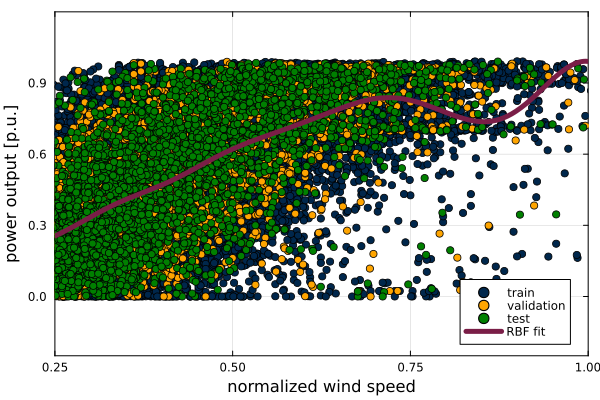

In [7]:
# 3 
# Example with new data, training/validation/testing split
# Data from the kaggle data set sorted by wind speed, data set split into training, validation, testing, windspeed 10m only feature

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)

df = CSV.read("location1.csv", DataFrame)
n  = nrow(df)

sort_index = sortperm(df.windspeed_10m)
t = Float64.(df.Power[sort_index])
x = Float64.(df.windspeed_10m[sort_index]) ./ 10.0

train, val, test = partition(eachindex(t), 0.8, 0.1; shuffle = true, rng = 128)

c = collect(0.0:0.05:1.1)
num_centers = length(c)

# Gaussian function
function design_matrix(xs, γ)
    Φ = zeros(length(xs), num_centers)
    for i in eachindex(xs), j in 1:num_centers
        Φ[i, j] = exp(-(γ * abs(xs[i] - c[j]))^2)
    end
    return Φ
end

function train_rbf(Φ, t; α = 0.01, iter_max = 25_000, λ = 0.001,
                   reg_type = "l2", seed = 128)
    rng = MersenneTwister(seed)
    ntrain = size(Φ, 1)
    w_0 = rand(rng)
    w   = rand(rng, num_centers)

    for _ in 1:iter_max
        i  = rand(rng, 1:ntrain)       # sample ONLY from the training rows
        ϕi = Φ[i, :]
        err = (w_0 + dot(ϕi, w)) - t[i]

        w_0 -= α * err
        w   .-= α * err .* ϕi

        if reg_type == "l2"
            w .-= α * λ .* w
        elseif reg_type == "l1"
            w .= sign.(w) .* max.(0, abs.(w) .- α * λ)
        end
    end
    return w_0, w
end

predict_rbf(Φ, w_0, w) = w_0 .+ Φ * w

# ---------- Hyperparameter selection on the validation set ----------
λ_grid = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
γ_grid = [2.0, 5.0, 10.0]

best = (rmse = Inf, λ = NaN, γ = NaN)
for γ in γ_grid, λ in λ_grid
    Φ_train = design_matrix(x[train], γ)
    Φ_val   = design_matrix(x[val],   γ)
    w_0, w  = train_rbf(Φ_train, t[train]; λ = λ)
    score   = rmse(predict_rbf(Φ_val, w_0, w), t[val])
    println("γ = $γ, λ = $λ → val RMSE = $(round(score, digits = 4))")
    if score < best.rmse
        global best = (rmse = score, λ = λ, γ = γ)
    end
end
println("Best: ", best)

# ---------- Final fit and test evaluation ----------
γ, λ = best.γ, best.λ

Φ_train = design_matrix(x[train], γ)
w_0, w  = train_rbf(Φ_train, t[train]; λ = λ)

Φ_test = design_matrix(x[test], γ)
println("Test RMSE = ", rmse(predict_rbf(Φ_test, w_0, w), t[test]))

# ---------- Plot ----------
φ(xv, j) = exp(-(γ * abs(xv - c[j]))^2)
w̅(xv) = w_0 + sum(w[j] * φ(xv, j) for j in 1:num_centers)

plo = scatter(x[train], t[train], c = blue,   label = "train", frame = :box,
              xlabel = "normalized wind speed", ylabel = "power output [p.u.]")
scatter!(plo, x[val],  t[val],  c = :orange, label = "validation")
scatter!(plo, x[test], t[test], c = :green,  label = "test")
plot!(plo, w̅, 0.25, 1.0, lw = 5, c = purple, label = "RBF fit")
plot!(plo, ylims = (-0.25, 1.2), xlims = (0.25, 1.0))
display(plo)

["2017-01-02 00:00:00", "2017-01-02 01:00:00", "2017-01-02 02:00:00"]
γ = 4.0, λ = 0.0005 → val RMSE = 0.1718
γ = 4.0, λ = 0.0002 → val RMSE = 0.1718
γ = 4.0, λ = 0.0001 → val RMSE = 0.1718
γ = 4.0, λ = 7.5e-5 → val RMSE = 0.1719
γ = 4.0, λ = 5.0e-5 → val RMSE = 0.1719
γ = 4.5, λ = 0.0005 → val RMSE = 0.1713
γ = 4.5, λ = 0.0002 → val RMSE = 0.1714
γ = 4.5, λ = 0.0001 → val RMSE = 0.1714
γ = 4.5, λ = 7.5e-5 → val RMSE = 0.1714
γ = 4.5, λ = 5.0e-5 → val RMSE = 0.1714
γ = 5.0, λ = 0.0005 → val RMSE = 0.1709
γ = 5.0, λ = 0.0002 → val RMSE = 0.1709
γ = 5.0, λ = 0.0001 → val RMSE = 0.171
γ = 5.0, λ = 7.5e-5 → val RMSE = 0.171
γ = 5.0, λ = 5.0e-5 → val RMSE = 0.171
γ = 6.0, λ = 0.0005 → val RMSE = 0.1703
γ = 6.0, λ = 0.0002 → val RMSE = 0.1703
γ = 6.0, λ = 0.0001 → val RMSE = 0.1703
γ = 6.0, λ = 7.5e-5 → val RMSE = 0.1703
γ = 6.0, λ = 5.0e-5 → val RMSE = 0.1703
γ = 7.0, λ = 0.0005 → val RMSE = 0.1702
γ = 7.0, λ = 0.0002 → val RMSE = 0.1702
γ = 7.0, λ = 0.0001 → val RMSE = 0.1702
γ = 7.0, λ = 

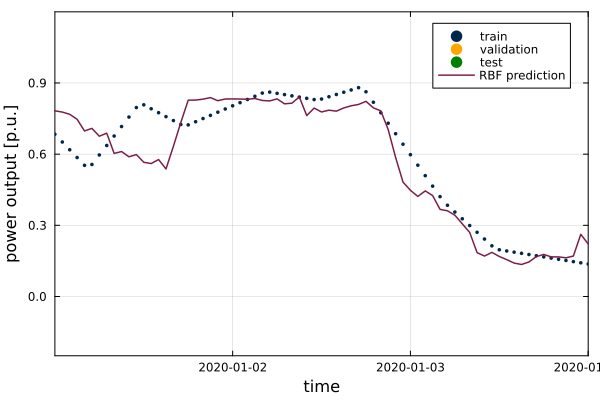

In [ ]:
# 4 
# Example with new data, data split, time sorting
# Data from the kaggle data set sorted by time, data set split into training, validation, testing, multiple wind features

df = CSV.read("location1.csv", DataFrame; types = Dict(:Time => String))
println(first(df.Time, 3))   

df.Time = DateTime.(df.Time, dateformat"yyyy-mm-dd HH:MM:SS")
sort!(df, :Time)

m     = nrow(df)
times = df.Time
t     = Float64.(df.Power)
x10m  = Float64.(df.windspeed_10m)  ./ 10.0
x100m = Float64.(df.windspeed_100m) ./ 10.0
x10g  = Float64.(df.windgusts_10m) ./ 10.0

train, val, test = partition(eachindex(t), 0.8, 0.1; shuffle = false, rng = 128)

x10_max = maximum(x10m)
c_max = max(1.1, maximum(x10m), maximum(x100m)) + 0.05
c = collect(0.0:0.05:c_max)
num_centers = length(c)

# RBF features for one input
function rbf_features(xs, γ)
    Φ = zeros(length(xs), num_centers)
    for i in eachindex(xs), j in 1:num_centers
        Φ[i, j] = exp(-(γ * abs(xs[i] - c[j]))^2)
    end
    return Φ
end

design_matrix(x1, x2, x3, γ) = hcat(rbf_features(x1, γ), rbf_features(x2, γ), rbf_features(x3, γ))

function train_rbf(Φ, t; α = 0.01, n_epochs = 20, λ = 0.001,
                   reg_type = :l2, seed = 128)
    reg_type in (:l2, :l1, :none) ||
        error("reg_type must be :l2, :l1, or :none, got $reg_type")

    rng    = MersenneTwister(seed)
    ntrain = size(Φ, 1)
    nfeat  = size(Φ, 2)
    w_0    = 0.0
    w      = zeros(nfeat)

    for epoch in 1:n_epochs
        for i in shuffle(rng, 1:ntrain)       # each sample visited once per epoch
            ϕi  = @view Φ[i, :]               # no allocation
            err = (w_0 + dot(ϕi, w)) - t[i]

            w_0 -= α * err
            w   .-= α * err .* ϕi

            if reg_type == :l2
                w .-= α * λ .* w
            elseif reg_type == :l1
                w .= sign.(w) .* max.(0, abs.(w) .- α * λ)
            end
        end
    end
    return w_0, w
end

predict_rbf(Φ, w_0, w) = w_0 .+ Φ * w

# ---------- Hyperparameter selection on the validation set ----------
λ_grid = [5e-4, 2e-4, 1e-4, 7.5e-5, 5e-5]
γ_grid = [ 4.0, 4.5, 5.0, 6.0, 7.0,]

best = (rmse = Inf, λ = NaN, γ = NaN)
for γ in γ_grid, λ in λ_grid
    Φ_train = design_matrix(x10m[train], x100m[train], x10g[train], γ)
    Φ_val   = design_matrix(x10m[val],   x100m[val], x10g[val],  γ)
    w_0, w  = train_rbf(Φ_train, t[train]; λ = λ)
    score   = rmse(predict_rbf(Φ_val, w_0, w), t[val])
    println("γ = $γ, λ = $λ → val RMSE = $(round(score, digits = 4))")
    if score < best.rmse
        global best = (rmse = score, λ = λ, γ = γ)
    end
end
println("Best: ", best)

# ---------- Final fit and test evaluation ----------
γ, λ = best.γ, best.λ

Φ_train = design_matrix(x10m[train], x100m[train], x10g[train], γ)
w_0, w  = train_rbf(Φ_train, t[train]; λ = λ)

Φ_test = design_matrix(x10m[test], x100m[test], x10g[test], γ)
println("Test RMSE = ", rmse(predict_rbf(Φ_test, w_0, w), t[test]))

# ---------- Plot (by time) ----------
ŷ = predict_rbf(design_matrix(x10m, x100m, x10g, γ), w_0, w)   # one prediction per timestamp

plo = scatter(times[train], t[train], c = blue, label = "train",
              ms = 2, markerstrokewidth = 0, frame = :box,
              xlabel = "time", ylabel = "power output [p.u.]")
scatter!(plo, times[val],  t[val],  c = :orange, ms = 2, markerstrokewidth = 0, label = "validation")
scatter!(plo, times[test], t[test], c = :green,  ms = 2, markerstrokewidth = 0, label = "test")
plot!(plo, times, ŷ, lw = 1.5, c = purple, label = "RBF prediction")
plot!(plo, ylims = (-0.25, 1.2))

# Zoom into two weeks if the data spans a long period (adjust the year):
plot!(plo, xlims = (DateTime(2020, 1, 1), DateTime(2020, 1, 4)))

display(plo)